In [1]:
# Import Libraries

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [2]:
# Load Dataset

df = pd.read_csv("datasets/airline_uncleandata.csv", low_memory=False)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully
Dataset shape: (100000, 24)


,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,75722,Female,Loyal Customer,20,Business travel,Eco,91,4,2,0,...,0,4,3,0,1,0,2,148,335,satisfied
1,80185,Male,Loyal Customer,17,Business travel,Business,3697,4,2,2,...,3,4,5,5,0,2,0,359,126,satisfied
2,19865,Female,Loyal Customer,14,Business travel,Business,1919,0,0,2,...,2,3,5,4,3,0,3,210,19,satisfied
3,76700,Male,Loyal Customer,52,Personal Travel,Eco Plus,2727,3,0,1,...,2,3,5,0,4,2,0,46,127,satisfied
4,92992,Male,disloyal Customer,15,Business travel,Business,3586,2,2,5,...,3,5,0,3,0,3,0,494,409,neutral or dissatisfied


In [3]:
# Understand the Dataset
# Rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print(df.columns.tolist())  # Column names

# Data types and missing values

df.info()
df.isnull().sum()

df.describe(include="all") # Numerical summary

print("Duplicate rows:", df.duplicated().sum())   # Duplicate records
print(df["satisfaction"].value_counts(dropna=False))  # #Target variable

Number of rows: 100000
Number of columns: 24
['id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype
---  ------                             --------------   -----
 0   id                                 100000 non-null  int64
 1   Gender                             99855 non-null   str  
 2   Customer Type                      99861 non-null   str  
 3   Age                                99872 non-null   str  
 4   Type of Travel

In [4]:
# Remove Duplicate Records
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (99000, 24)
Remaining duplicates: 0


In [5]:
# Clean Text Columns

# Find Text columns 
text_cols = df.select_dtypes(include=["object", "str"]).columns

# Remove Extra spaces
for col in text_cols:
    df[col] = df[col].str.strip()

# Unknown values convert missing 
df = df.replace(["?", "Unknown", "unknown", ""], np.nan)

print("Text cleaning completed")

print(df["Gender"].value_counts(dropna=False))
print(df["satisfaction"].value_counts(dropna=False))

Text cleaning completed
Gender
Male      49395
Female    49219
NaN         266
Malee        61
Femle        59
Name: count, dtype: int64
satisfaction
neutral or dissatisfied    54356
satisfied                  44445
NaN                           76
Satisfied                     68
Unsatisfied                   55
Name: count, dtype: int64


In [6]:
# Clean Categorical Values

# Gender clean 
df["Gender"] = df["Gender"].replace({
    "Malee": "Male",
    "Femle": "Female",
    "male": "Male",
    "female": "Female"
})

# Customer Type clean 
df["Customer Type"] = df["Customer Type"].replace({
    "Loyal customer": "Loyal Customer",
    "Disloyal Customer": "disloyal Customer"
})

# Type of Travel clean
df["Type of Travel"] = df["Type of Travel"].replace({
    "Business": "Business travel",
    "Personal": "Personal Travel"
})

# Class clean
df["Class"] = df["Class"].replace({
    "EcoPlus": "Eco Plus",
    "Economy": "Eco"
})

# Target variable clean 
df["satisfaction"] = df["satisfaction"].replace({
    "Satisfied": "satisfied",
    "Unsatisfied": "neutral or dissatisfied"
})

print(df["satisfaction"].value_counts(dropna=False))

satisfaction
neutral or dissatisfied    54411
satisfied                  44513
NaN                           76
Name: count, dtype: int64


In [7]:
# Convert Numerical Columns
numeric_cols = [
    "Age",
    "Flight Distance",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_cols].dtypes)

Age                                  float64
Flight Distance                      float64
Inflight wifi service                float64
Departure/Arrival time convenient    float64
Ease of Online booking               float64
Gate location                        float64
Food and drink                       float64
Online boarding                      float64
Seat comfort                         float64
Inflight entertainment               float64
On-board service                     float64
Leg room service                     float64
Baggage handling                     float64
Checkin service                      float64
Inflight service                     float64
Cleanliness                          float64
Departure Delay in Minutes           float64
Arrival Delay in Minutes             float64
dtype: object


In [8]:
# Handle Invalid Numerical Values

# Age: allowed range 0 to 100
df.loc[(df["Age"] < 0) | (df["Age"] > 100), "Age"] = np.nan

# Flight distance: negative distance not allowed
df.loc[df["Flight Distance"] < 0, "Flight Distance"] = np.nan

# Service ratings: 0 to 5
rating_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness"
]

for col in rating_cols:
    df.loc[(df[col] < 0) | (df[col] > 5), col] = np.nan
    
# Delay: negative values not allowed
delay_cols = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

for col in delay_cols:
    df.loc[df[col] < 0, col] = np.nan

print("Invalid numerical values handled")

Invalid numerical values handled


In [9]:
# Handle Missing Values
# Numerical columns median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns mode
cat_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled")

df = df.dropna(subset=["satisfaction"])

print("Remaining missing target values:", df["satisfaction"].isnull().sum())

Missing values handled
Remaining missing target values: 0


In [10]:
# Remove Unnecessary ID Column
df = df.drop(columns=["id"], errors="ignore")

print("Shape after cleaning:", df.shape)

Shape after cleaning: (98924, 23)


In [11]:
# Final Data Cleaning Check
print("Missing values in dataset:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nFinal dataset shape:")
print(df.shape)

print("\nTarget distribution:")
print(df["satisfaction"].value_counts())

df.head()

Missing values in dataset: 0
Duplicate rows: 0

Final dataset shape:
(98924, 23)

Target distribution:
satisfaction
neutral or dissatisfied    54411
satisfied                  44513
Name: count, dtype: int64


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Female,Loyal Customer,20.0,Business travel,Eco,91.0,4.0,2.0,0.0,1.0,...,0.0,4.0,3.0,0.0,1.0,0.0,2.0,148.0,335.0,satisfied
1,Male,Loyal Customer,17.0,Business travel,Business,3697.0,4.0,2.0,2.0,2.0,...,3.0,4.0,5.0,5.0,0.0,2.0,0.0,359.0,126.0,satisfied
2,Female,Loyal Customer,14.0,Business travel,Business,1919.0,0.0,0.0,2.0,0.0,...,2.0,3.0,5.0,4.0,3.0,0.0,3.0,210.0,19.0,satisfied
3,Male,Loyal Customer,52.0,Personal Travel,Eco Plus,2727.0,3.0,0.0,1.0,1.0,...,2.0,3.0,5.0,0.0,4.0,2.0,0.0,46.0,127.0,satisfied
4,Male,disloyal Customer,15.0,Business travel,Business,3586.0,2.0,2.0,5.0,3.0,...,3.0,5.0,0.0,3.0,0.0,3.0,0.0,494.0,409.0,neutral or dissatisfied


In [12]:
# Save Cleaned Dataset
df.to_csv("clean-datasets/airline_cleaned.csv", index=False)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


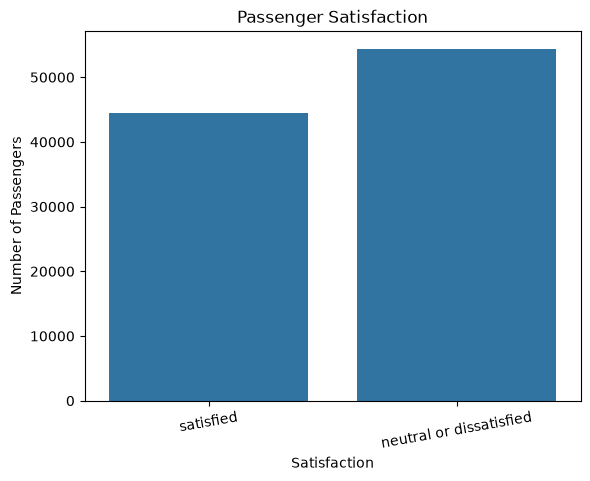

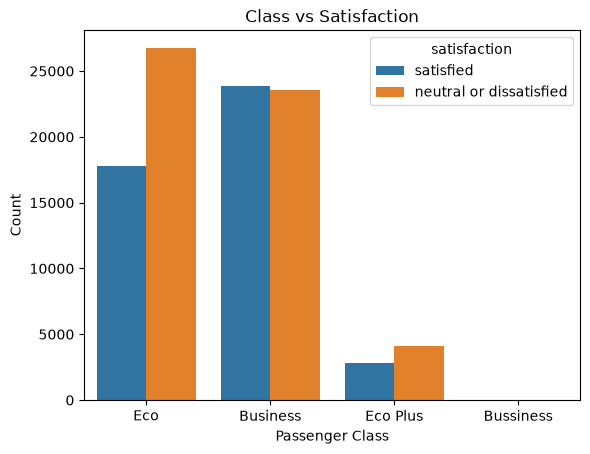

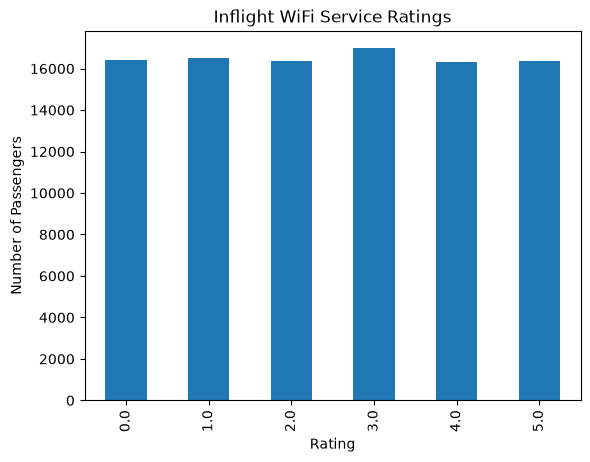

In [13]:
# Exploratory Data Analysis (EDA)
# Satisfaction Count
sns.countplot(data=df, x="satisfaction")

plt.title("Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=10)
plt.show()

# Class vs Satisfaction
sns.countplot(data=df, x="Class", hue="satisfaction")

plt.title("Class vs Satisfaction")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

# Service Ratings
df["Inflight wifi service"].value_counts().sort_index().plot(kind="bar")

plt.title("Inflight WiFi Service Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Passengers")
plt.show()

In [14]:
# Prepare Features and Target
X = df.drop("satisfaction", axis=1)
y = df["satisfaction"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (98924, 22)
Target shape: (98924,)


In [15]:
# Split the Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 79139
Testing records: 19785


In [16]:
# Convert Categorical Features into Numbers
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

# two datasets same columns 
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (79139, 24)
Testing features: (19785, 24)


In [17]:
# Build Classification Model
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully")

Decision Tree model trained successfully


In [18]:
# Predict Passenger Satisfaction
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
['satisfied', 'satisfied', 'neutral or dissatisfied', 'neutral or dissatisfied', 'neutral or dissatisfied', 'satisfied', 'satisfied', 'satisfied', 'neutral or dissatisfied', 'neutral or dissatisfied']

First 10 predicted values:
['neutral or dissatisfied' 'neutral or dissatisfied'
 'neutral or dissatisfied' 'neutral or dissatisfied'
 'neutral or dissatisfied' 'satisfied' 'satisfied' 'satisfied'
 'neutral or dissatisfied' 'neutral or dissatisfied']


In [19]:
# Calculate Classification Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Classification Accuracy:", round(accuracy * 100, 2), "%")

Classification Accuracy: 75.4 %


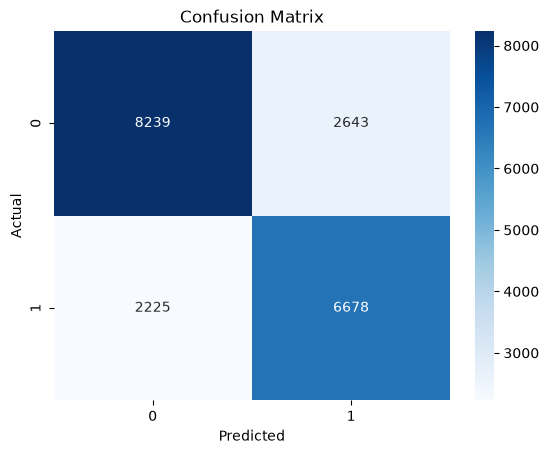

In [20]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [21]:
# Classification Report
print(classification_report(y_test, y_pred))

                         precision    recall  f1-score   support

neutral or dissatisfied       0.79      0.76      0.77     10882
              satisfied       0.72      0.75      0.73      8903

               accuracy                           0.75     19785
              macro avg       0.75      0.75      0.75     19785
           weighted avg       0.76      0.75      0.75     19785

